# RAF-DB preprocessing for MobileNetV2

## 1. Imports and settings

In [84]:
from pathlib import Path
import hashlib
import random
import sys
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from PIL import Image, UnidentifiedImageError
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    f1_score,
    precision_score,
    recall_score,
)
from sklearn.model_selection import train_test_split
import torch
from torch import nn
from torch.utils.data import DataLoader, Dataset, WeightedRandomSampler
import torchvision
from torchvision import transforms
from torchvision.models import (
    EfficientNet_B0_Weights,
    MobileNet_V2_Weights,
    MobileNet_V3_Large_Weights,
    ResNet18_Weights,
    efficientnet_b0,
    mobilenet_v2,
    mobilenet_v3_large,
    resnet18,
)


RAF_ALIGNED_IMAGE_DIR = Path(r"RAF-DB/DATASET")
RAF_LABEL_FILE = Path(r"RAF-DB/train_labels.csv")  # The test labels will be detected automatically

IMAGE_SIZE = 128
BATCH_SIZE = 128
NUM_WORKERS = 0
VALIDATION_SPLIT = 0.10
RANDOM_SEED = 42

random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)
torch.manual_seed(RANDOM_SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(RANDOM_SEED)

## 2. CUDA check

In [85]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"PyTorch version: {torch.__version__}")
print(f"CUDA available: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")
print(f"Selected device: {device}")

PyTorch version: 2.12.0+cu130
CUDA available: True
GPU: NVIDIA GeForce RTX 5070 Ti
Selected device: cuda


## 3. RAF-DB class names and label mapping

In [86]:
CLASS_NAMES = [
    "Surprise",
    "Fear",
    "Disgust",
    "Happy",
    "Sad",
    "Angry",
    "Neutral",
]
ORIGINAL_LABEL_TO_NAME = {index + 1: name for index, name in enumerate(CLASS_NAMES)}
ORIGINAL_LABEL_TO_INDEX = {index + 1: index for index in range(len(CLASS_NAMES))}
ORIGINAL_LABEL_TO_NAME

{1: 'Surprise',
 2: 'Fear',
 3: 'Disgust',
 4: 'Happy',
 5: 'Sad',
 6: 'Angry',
 7: 'Neutral'}

## 4. Load RAF-DB labels and image paths

In [87]:
raf_frames = []
for split in ["train", "test"]:
    frame = pd.read_csv(RAF_LABEL_FILE.parent / f"{split}_labels.csv")
    frame["official_split"] = split
    frame["image_path"] = [
        RAF_ALIGNED_IMAGE_DIR / split / str(label) / filename
        for filename, label in zip(frame["image"], frame["label"])
    ]
    raf_frames.append(frame)

raf_dataframe = pd.concat(raf_frames, ignore_index=True).rename(
    columns={"image": "source_filename", "label": "original_label"}
)
raf_dataframe["label_index"] = raf_dataframe["original_label"].map(ORIGINAL_LABEL_TO_INDEX)
raf_dataframe["label_name"] = raf_dataframe["original_label"].map(ORIGINAL_LABEL_TO_NAME)
raf_dataframe = raf_dataframe[
    ["image_path", "original_label", "label_index", "label_name", "official_split"]
].copy()
raf_dataframe.head()

,image_path,original_label,label_index,label_name,official_split
0,RAF-DB\DATASET\train\5\train_00001_aligned.jpg,5,4,Sad,train
1,RAF-DB\DATASET\train\5\train_00002_aligned.jpg,5,4,Sad,train
2,RAF-DB\DATASET\train\4\train_00003_aligned.jpg,4,3,Happy,train
3,RAF-DB\DATASET\train\4\train_00004_aligned.jpg,4,3,Happy,train
4,RAF-DB\DATASET\train\5\train_00005_aligned.jpg,5,4,Sad,train


## 5. Luminance and contrast check

Images that are too dark, too bright, or possess low contrast are flagged and may be pruned utilising a flag.

Flagged 65 of 15,339 images.
Category counts can overlap when an image has more than one issue.


,count
too_dark,29
too_bright,1
low_contrast,44


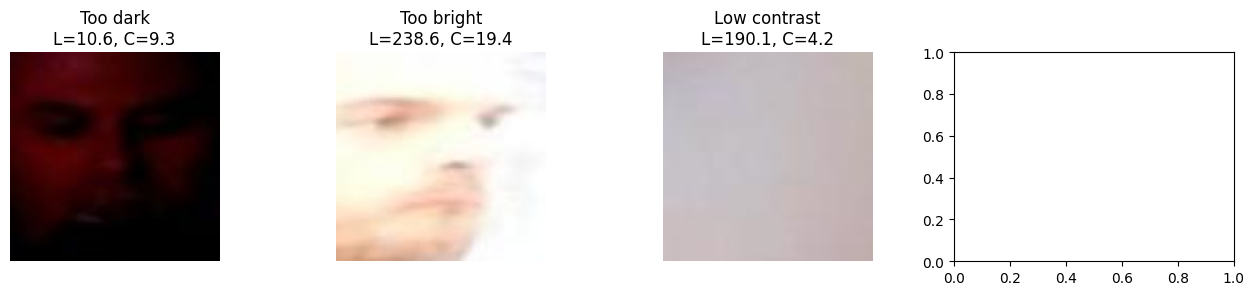

Removed 51 rows from the official training pool.


In [88]:
REMOVE_FLAGGED_TRAINING_IMAGES = True
LUMINANCE_MIN, LUMINANCE_MAX = 30, 235
CONTRAST_MIN = 15

def image_stats(image_path):
    with Image.open(image_path) as image:
        pixels = np.asarray(image.convert("L"), dtype=np.float32)
    return pd.Series({"luminance": pixels.mean(), "contrast": pixels.std()})

image_quality = raf_dataframe[["image_path", "official_split", "label_name"]].copy()
image_quality[["luminance", "contrast"]] = image_quality["image_path"].apply(image_stats)
image_quality["too_dark"] = image_quality["luminance"] < LUMINANCE_MIN
image_quality["too_bright"] = image_quality["luminance"] > LUMINANCE_MAX
image_quality["low_contrast"] = image_quality["contrast"] < CONTRAST_MIN
quality_categories = ["too_dark", "too_bright", "low_contrast"]
image_quality["flagged"] = image_quality[quality_categories].any(axis=1)
flagged_images = image_quality[image_quality["flagged"]].reset_index(drop=True)

print(f"Flagged {len(flagged_images):,} of {len(image_quality):,} images.")
print("Category counts can overlap when an image has more than one issue.")
display(image_quality[quality_categories].sum().rename("count").to_frame())

sample_indices = {
    "Too dark": image_quality["luminance"].idxmin(),
    "Too bright": image_quality["luminance"].idxmax(),
    "Low contrast": image_quality["contrast"].idxmin()
}
fig, axes = plt.subplots(1, 4, figsize=(13, 3))
for axis, (category, index) in zip(axes, sample_indices.items()):
    row = image_quality.loc[index]
    with Image.open(row["image_path"]) as image:
        axis.imshow(image)
    axis.set_title(
        f"{category}\nL={row['luminance']:.1f}, C={row['contrast']:.1f}"
    )
    axis.axis("off")
plt.tight_layout()
plt.show()

if REMOVE_FLAGGED_TRAINING_IMAGES:
    flagged_training_paths = flagged_images.loc[
        flagged_images["official_split"] == "train", "image_path"
    ]
    before = len(raf_dataframe)
    raf_dataframe = raf_dataframe[
        ~raf_dataframe["image_path"].isin(flagged_training_paths)
    ].reset_index(drop=True)
    print(f'Removed {before - len(raf_dataframe):,} rows from the official training pool.')

## 6. Create train, validation and test DataFrames

In [89]:
official_train_dataframe = raf_dataframe[raf_dataframe["official_split"] == "train"].copy()
test_dataframe = raf_dataframe[raf_dataframe["official_split"] == "test"].copy()

if official_train_dataframe.empty or test_dataframe.empty:
    raise ValueError(
        "The label file must contain both official train_ and test_ entries; "
        "official test images must not be created from the training set."
    )

train_dataframe, validation_dataframe = train_test_split(
    official_train_dataframe,
    test_size=VALIDATION_SPLIT,
    random_state=RANDOM_SEED,
    stratify=official_train_dataframe["label_index"],
)

train_dataframe = train_dataframe.reset_index(drop=True)
validation_dataframe = validation_dataframe.reset_index(drop=True)
test_dataframe = test_dataframe.reset_index(drop=True)

## 7. Display split and class distributions

Split sizes:
  train: 10,998
  validation: 1,222
  test: 3,068


,train,validation,test
label_name,,,
Surprise,1157,129,329
Fear,253,28,74
Disgust,644,72,160
Happy,4274,475,1185
Sad,1783,198,478
Angry,631,70,162
Neutral,2256,250,680


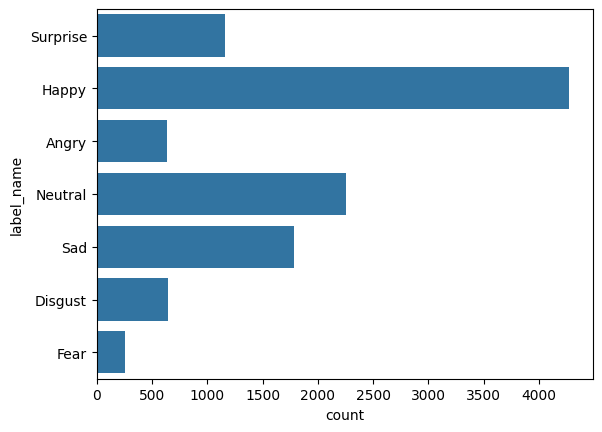

In [90]:
split_dataframes = {
    "train": train_dataframe,
    "validation": validation_dataframe,
    "test": test_dataframe,
}

print("Split sizes:")
for split_name, split_dataframe in split_dataframes.items():
    print(f"  {split_name}: {len(split_dataframe):,}")

class_distribution = pd.DataFrame({
    split_name: split_dataframe["label_name"].value_counts().reindex(CLASS_NAMES, fill_value=0)
    for split_name, split_dataframe in split_dataframes.items()
})
display(class_distribution)

sns.countplot(split_dataframes['train']['label_name'])
plt.show()

# missing_paths = raf_dataframe[~raf_dataframe["image_path"].map(Path.is_file)]
# duplicate_paths = raf_dataframe[raf_dataframe["image_path"].duplicated(keep=False)]
# invalid_labels = raf_dataframe[~raf_dataframe["original_label"].between(1, 7)]

# print(f"Missing image paths: {len(missing_paths)}")
# print(f"Duplicate image paths: {len(duplicate_paths)}")
# print(f"Invalid labels: {len(invalid_labels)}")
# if not missing_paths.empty:
#     print("WARNING: sample missing paths:")
#     print(missing_paths["image_path"].head().to_string(index=False))
# if not duplicate_paths.empty:
#     print("WARNING: sample duplicate paths:")
#     print(duplicate_paths["image_path"].head().to_string(index=False))
# if not invalid_labels.empty:
#     print("WARNING: invalid label rows:")
#     print(invalid_labels.head())
# if not missing_paths.empty or not duplicate_paths.empty or not invalid_labels.empty:
#     raise ValueError("Fix the RAF-DB metadata issues printed above before continuing.")

# unreadable_paths = []
# for image_path in raf_dataframe["image_path"]:
#     try:
#         with Image.open(image_path) as image:
#             image.verify()
#     except (OSError, UnidentifiedImageError) as error:
#         unreadable_paths.append((image_path, str(error)))

# print(f"Unreadable images: {len(unreadable_paths)}")
# if unreadable_paths:
#     print("WARNING: sample unreadable images:")
#     for path, error in unreadable_paths[:5]:
#         print(f"  {path}: {error}")
#     raise ValueError("Unreadable RAF-DB images were found; fix them before continuing.")

## 8. Define training and evaluation transforms

In [91]:
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

train_transform = transforms.Compose([
    transforms.Grayscale(num_output_channels=3),
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomAffine(degrees=8, translate=(0.04, 0.04), scale=(0.95, 1.05)),
    transforms.ColorJitter(brightness=0.1, contrast=0.1),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
])

evaluation_transform = transforms.Compose([
    transforms.Grayscale(num_output_channels=3),
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
])

# RGB equivalents retain every setting except grayscale conversion.
rgb_train_transform = transforms.Compose(train_transform.transforms[1:])
rgb_evaluation_transform = transforms.Compose(evaluation_transform.transforms[1:])

train_transform, evaluation_transform, rgb_train_transform, rgb_evaluation_transform

(Compose(
     Grayscale(num_output_channels=3)
     Resize(size=(128, 128), interpolation=bilinear, max_size=None, antialias=True)
     RandomHorizontalFlip(p=0.5)
     RandomAffine(degrees=[-8.0, 8.0], translate=(0.04, 0.04), scale=(0.95, 1.05))
     ColorJitter(brightness=(0.9, 1.1), contrast=(0.9, 1.1), saturation=None, hue=None)
     ToTensor()
     Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
 ),
 Compose(
     Grayscale(num_output_channels=3)
     Resize(size=(128, 128), interpolation=bilinear, max_size=None, antialias=True)
     ToTensor()
     Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
 ),
 Compose(
     Resize(size=(128, 128), interpolation=bilinear, max_size=None, antialias=True)
     RandomHorizontalFlip(p=0.5)
     RandomAffine(degrees=[-8.0, 8.0], translate=(0.04, 0.04), scale=(0.95, 1.05))
     ColorJitter(brightness=(0.9, 1.1), contrast=(0.9, 1.1), saturation=None, hue=None)
     ToTensor()
     Normalize(mean=[0.485, 0.456, 0.4

## 9. Define the PyTorch Dataset class

In [92]:
class RAFDBDataset(Dataset):
    def __init__(self, dataframe, transform):
        self.dataframe = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):
        row = self.dataframe.iloc[index]
        image_path = Path(row["image_path"])
        try:
            with Image.open(image_path) as image:
                image = image.convert("RGB")
                image_tensor = self.transform(image)
        except (OSError, UnidentifiedImageError) as error:
            raise RuntimeError(f"Could not load image {image_path}: {error}") from error

        label_index = int(row["label_index"])
        return image_tensor, label_index, str(image_path)

## 10. Create DataLoaders

In [93]:
train_dataset = RAFDBDataset(train_dataframe, train_transform)
validation_dataset = RAFDBDataset(validation_dataframe, evaluation_transform)
test_dataset = RAFDBDataset(test_dataframe, evaluation_transform)

loader_options = {
    "batch_size": BATCH_SIZE,
    "num_workers": NUM_WORKERS,
    "pin_memory": torch.cuda.is_available(),
}
if NUM_WORKERS > 0:
    loader_options["persistent_workers"] = True

train_loader = DataLoader(train_dataset, shuffle=True, **loader_options)
validation_loader = DataLoader(validation_dataset, shuffle=False, **loader_options)
test_loader = DataLoader(test_dataset, shuffle=False, **loader_options)

print(f"Training batches: {len(train_loader)}")
print(f"Validation batches: {len(validation_loader)}")
print(f"Test batches: {len(test_loader)}")

Training batches: 86
Validation batches: 10
Test batches: 24


## 11. Preview original and transformed images

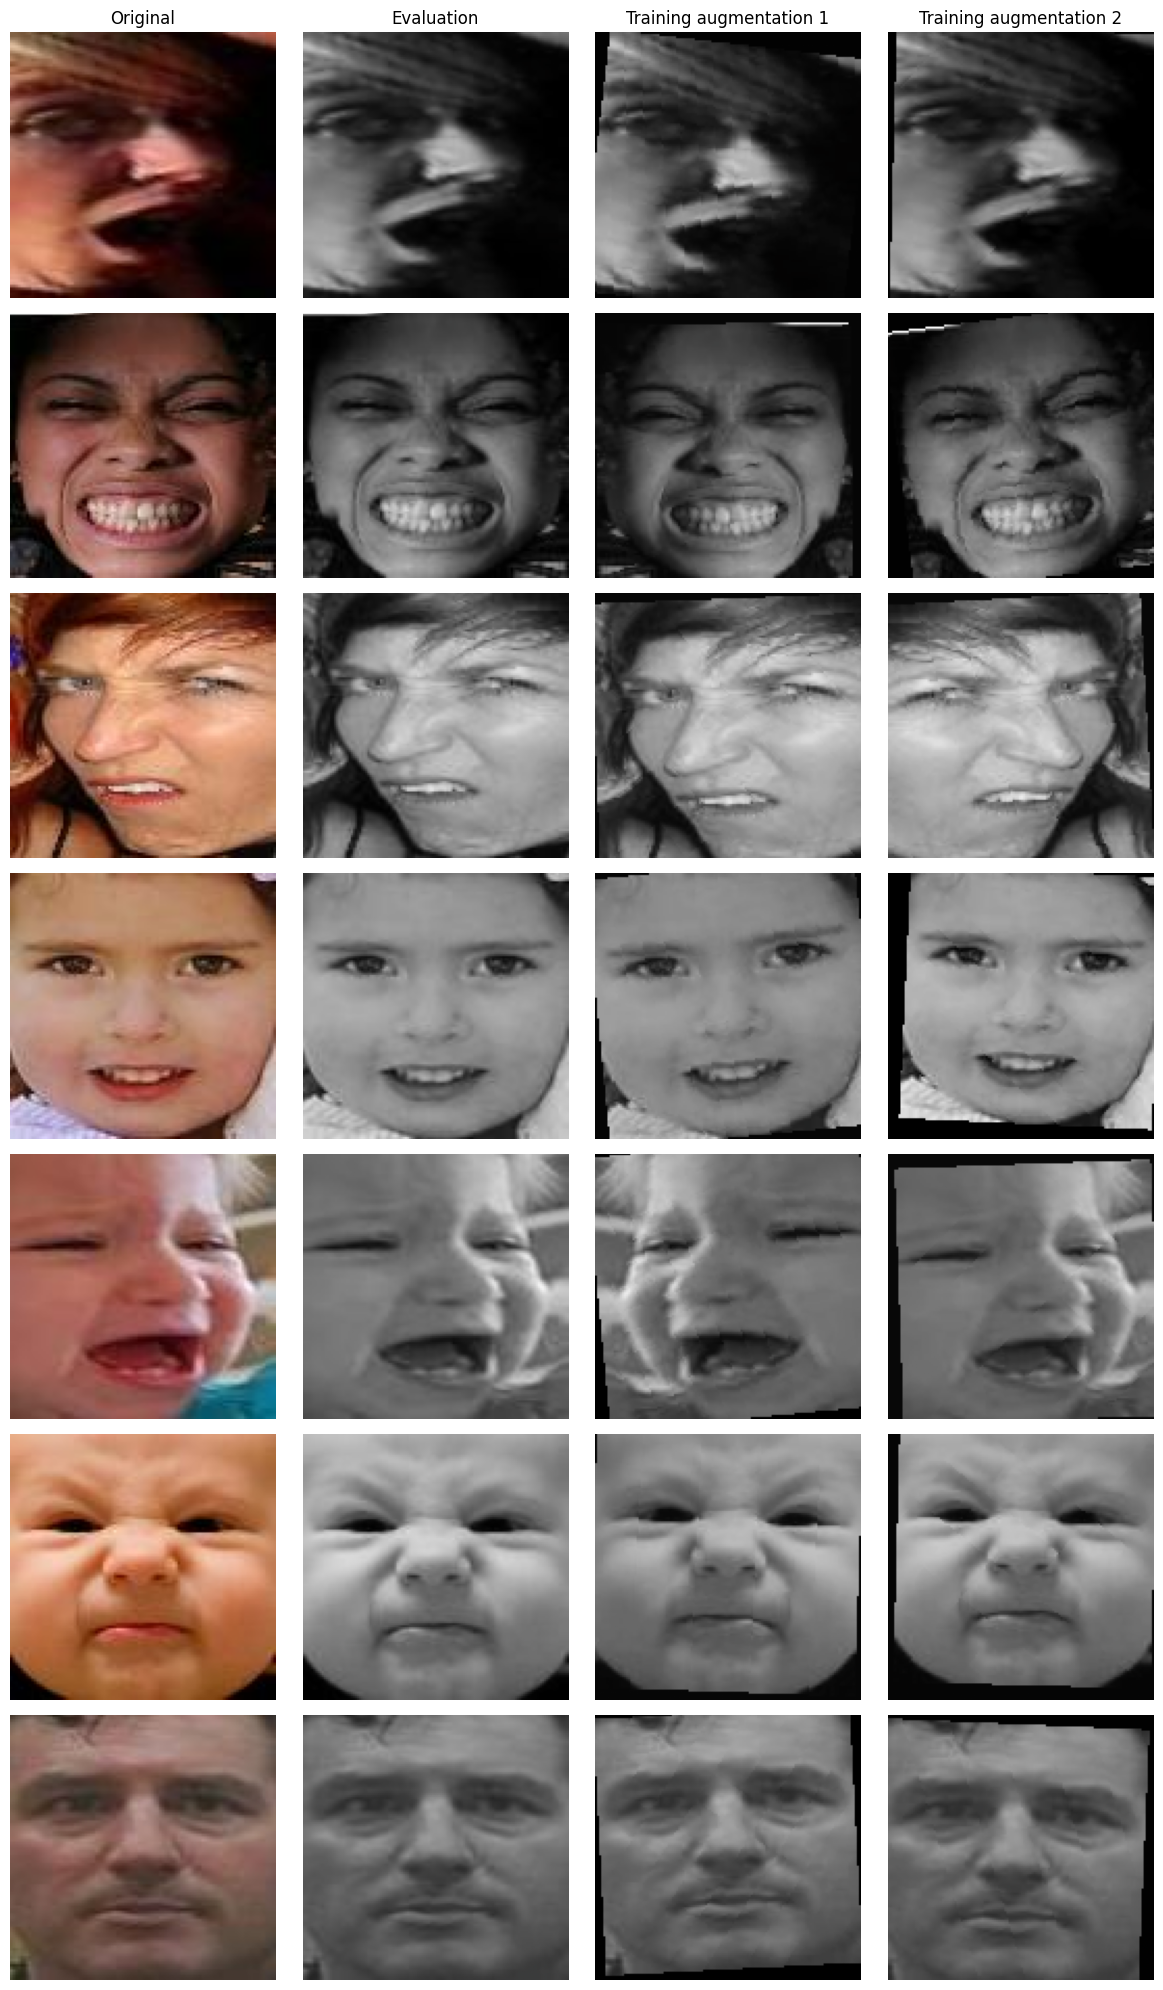

In [94]:
mean_tensor = torch.tensor(IMAGENET_MEAN).view(3, 1, 1)
std_tensor = torch.tensor(IMAGENET_STD).view(3, 1, 1)

def tensor_for_display(tensor):
    return (tensor.cpu() * std_tensor + mean_tensor).clamp(0, 1).permute(1, 2, 0).numpy()

fig, axes = plt.subplots(len(CLASS_NAMES), 4, figsize=(12, 20))
column_titles = ["Original", "Evaluation", "Training augmentation 1", "Training augmentation 2"]
for column, title in enumerate(column_titles):
    axes[0, column].set_title(title)

for label_index, class_name in enumerate(CLASS_NAMES):
    class_row = train_dataframe[train_dataframe["label_index"] == label_index].iloc[0]
    with Image.open(class_row["image_path"]) as loaded_image:
        original = loaded_image.convert("RGB")
        previews = [
            np.asarray(original),
            tensor_for_display(evaluation_transform(original)),
            tensor_for_display(train_transform(original)),
            tensor_for_display(train_transform(original)),
        ]

    for column, preview in enumerate(previews):
        axes[label_index, column].imshow(preview)
        axes[label_index, column].axis("off")
        axes[label_index, column].set_ylabel(class_name if column == 0 else "")

plt.tight_layout()
plt.show()

# MobileNetV2 training and evaluation

## 1. Training settings

In [95]:
TINY_OVERFIT_SAMPLES = 32
TINY_OVERFIT_EPOCHS = 15

STAGE_1_EPOCHS = 4
STAGE_1_LR = 1e-3

STAGE_2_EPOCHS = 15
STAGE_2_LR = 1e-4

WEIGHT_DECAY = 1e-4
EARLY_STOPPING_PATIENCE = 5
REQUIRE_CUDA = True  # Stop instead of silently training on the CPU.

STAGE_1_CHECKPOINT = Path("best_mobilenetv2_stage1.pt")
BASELINE_CHECKPOINT = Path("best_mobilenetv2_baseline.pt")
NO_AUGMENTATION_STAGE_1_CHECKPOINT = Path("best_mobilenetv2_no_augmentation_stage1.pt")
NO_AUGMENTATION_CHECKPOINT = Path("best_mobilenetv2_no_augmentation.pt")
WEIGHTED_STAGE_1_CHECKPOINT = Path("best_mobilenetv2_weighted_stage1.pt")
WEIGHTED_CHECKPOINT = Path("best_mobilenetv2_weighted.pt")
OVERSAMPLED_STAGE_1_CHECKPOINT = Path("best_mobilenetv2_oversampled_stage1.pt")
OVERSAMPLED_CHECKPOINT = Path("best_mobilenetv2_oversampled.pt")
RGB_OVERSAMPLED_STAGE_1_CHECKPOINT = Path("best_mobilenetv2_rgb_oversampled_stage1.pt")
RGB_OVERSAMPLED_CHECKPOINT = Path("best_mobilenetv2_rgb_oversampled.pt")
MOBILENETV3_STAGE_1_CHECKPOINT = Path("best_mobilenetv3_large_stage1.pt")
MOBILENETV3_CHECKPOINT = Path("best_mobilenetv3_large.pt")
EFFICIENTNET_STAGE_1_CHECKPOINT = Path("best_efficientnet_b0_stage1.pt")
EFFICIENTNET_CHECKPOINT = Path("best_efficientnet_b0.pt")
RESNET18_STAGE_1_CHECKPOINT = Path("best_resnet18_stage1.pt")
RESNET18_CHECKPOINT = Path("best_resnet18.pt")

# Experiment controls
SKIP_ALL_EXPERIMENTS = False
RUN_EXPERIMENT_1 = True   # MobileNetV2 baseline
RUN_EXPERIMENT_2 = True   # MobileNetV2 without augmentation
RUN_EXPERIMENT_3 = True   # MobileNetV2 with class weighting
RUN_EXPERIMENT_4 = True   # MobileNetV2 with oversampling
RUN_EXPERIMENT_5 = True  # MobileNetV2 RGB with oversampling
RUN_EXPERIMENT_6 = True   # MobileNetV3-Large baseline
RUN_EXPERIMENT_7 = True   # EfficientNet-B0 RGB with oversampling
RUN_EXPERIMENT_8 = True   # ResNet-18 RGB with oversampling

if (
    REQUIRE_CUDA
    and device.type != "cuda"
    and not SKIP_ALL_EXPERIMENTS
    and any([
        RUN_EXPERIMENT_1, RUN_EXPERIMENT_2, RUN_EXPERIMENT_3,
        RUN_EXPERIMENT_4, RUN_EXPERIMENT_5, RUN_EXPERIMENT_6,
        RUN_EXPERIMENT_7, RUN_EXPERIMENT_8,
    ])
):
    raise RuntimeError(
        "CUDA is required for training but is not available. Check your NVIDIA driver "
        "and install a CUDA-enabled PyTorch build before continuing."
    )

if device.type == "cuda":
    print(f"Training will use GPU: {torch.cuda.get_device_name(device)}")
    print(f"Model and batches will be placed on: {device}")

if SKIP_ALL_EXPERIMENTS:
    RUN_EXPERIMENT_1 = False
    RUN_EXPERIMENT_2 = False
    RUN_EXPERIMENT_3 = False
    RUN_EXPERIMENT_4 = False
    RUN_EXPERIMENT_5 = False
    RUN_EXPERIMENT_6 = False
    RUN_EXPERIMENT_7 = False
    RUN_EXPERIMENT_8 = False

RUN_TINY_OVERFIT_TEST = (
    not SKIP_ALL_EXPERIMENTS
    and any([
        RUN_EXPERIMENT_1, RUN_EXPERIMENT_2, RUN_EXPERIMENT_3,
        RUN_EXPERIMENT_4, RUN_EXPERIMENT_5, RUN_EXPERIMENT_6,
        RUN_EXPERIMENT_7, RUN_EXPERIMENT_8,
    ])
)
experiment_flags = {
    "Experiment 1 - MobileNetV2 baseline": RUN_EXPERIMENT_1,
    "Experiment 2 - No augmentation": RUN_EXPERIMENT_2,
    "Experiment 3 - Class-weighted": RUN_EXPERIMENT_3,
    "Experiment 4 - Oversampled": RUN_EXPERIMENT_4,
    "Experiment 5 - RGB oversampled MobileNetV2": RUN_EXPERIMENT_5,
    "Experiment 6 - MobileNetV3-Large": RUN_EXPERIMENT_6,
    "Experiment 7 - RGB oversampled EfficientNet-B0": RUN_EXPERIMENT_7,
    "Experiment 8 - RGB oversampled ResNet-18": RUN_EXPERIMENT_8,
}
print("Experiment flags:")
for experiment_name, enabled in experiment_flags.items():
    print(f"  {experiment_name}: {'RUN' if enabled else 'SKIP'}")

Training will use GPU: NVIDIA GeForce RTX 5070 Ti
Model and batches will be placed on: cuda
Experiment flags:
  Experiment 1 - MobileNetV2 baseline: RUN
  Experiment 2 - No augmentation: RUN
  Experiment 3 - Class-weighted: RUN
  Experiment 4 - Oversampled: RUN
  Experiment 5 - RGB oversampled MobileNetV2: RUN
  Experiment 6 - MobileNetV3-Large: RUN
  Experiment 7 - RGB oversampled EfficientNet-B0: RUN
  Experiment 8 - RGB oversampled ResNet-18: RUN


## 2. MobileNetV2 model

In [96]:
def reset_experiment_seed():
    random.seed(RANDOM_SEED)
    np.random.seed(RANDOM_SEED)
    torch.manual_seed(RANDOM_SEED)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(RANDOM_SEED)


def create_model():
    model = mobilenet_v2(weights=MobileNet_V2_Weights.DEFAULT)
    model.classifier = nn.Sequential(
        nn.Dropout(p=0.2),
        nn.Linear(model.last_channel, len(CLASS_NAMES)),
    )
    return model.to(device)


def load_model_weights(model, checkpoint_path):
    # weights_only is preferred, with a fallback for older PyTorch versions.
    try:
        state_dict = torch.load(checkpoint_path, map_location=device, weights_only=True)
    except TypeError:
        state_dict = torch.load(checkpoint_path, map_location=device)
    model.load_state_dict(state_dict)
    return model

## 3. Reusable training and validation functions

In [112]:
def calculate_accuracy_and_macro_f1(targets, predictions):
    accuracy = accuracy_score(targets, predictions)
    macro_f1 = f1_score(targets, predictions, average="macro", zero_division=0)
    return accuracy, macro_f1


def train_one_epoch(
    model, loader, criterion, optimizer, frozen_features=False, trainable_head=None,
):
    model.train()
    if frozen_features:
        # Freeze BatchNorm statistics while keeping the classification head trainable.
        model.eval()
        head = trainable_head if trainable_head is not None else model.classifier
        head.train()

    running_loss = 0.0
    all_targets = []
    all_predictions = []

    for images, labels, _ in loader:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)
        logits = model(images)
        loss = criterion(logits, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)
        all_targets.extend(labels.detach().cpu().tolist())
        all_predictions.extend(logits.argmax(dim=1).detach().cpu().tolist())

    epoch_loss = running_loss / len(loader.dataset)
    epoch_accuracy, _ = calculate_accuracy_and_macro_f1(all_targets, all_predictions)
    return epoch_loss, epoch_accuracy


@torch.inference_mode()
def validate_one_epoch(model, loader, criterion):
    model.eval()
    running_loss = 0.0
    all_targets = []
    all_predictions = []

    for images, labels, _ in loader:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)
        logits = model(images)
        loss = criterion(logits, labels)

        running_loss += loss.item() * images.size(0)
        all_targets.extend(labels.cpu().tolist())
        all_predictions.extend(logits.argmax(dim=1).cpu().tolist())

    epoch_loss = running_loss / len(loader.dataset)
    epoch_accuracy, epoch_macro_f1 = calculate_accuracy_and_macro_f1(
        all_targets, all_predictions
    )
    return epoch_loss, epoch_accuracy, epoch_macro_f1


def save_best_checkpoint(model, validation_macro_f1, best_macro_f1, checkpoint_path):
    improved = validation_macro_f1 > best_macro_f1
    if improved:
        torch.save(model.state_dict(), checkpoint_path)
        best_macro_f1 = validation_macro_f1
        print(f"  Saved improved checkpoint to {checkpoint_path}")
    return best_macro_f1, improved


def run_training_stage(
    model, train_data_loader, optimizer, criterion, epochs, stage_name, checkpoint_path,
    frozen_features=False, early_stopping_patience=None, validation_data_loader=None,
    trainable_head=None,
):
    if validation_data_loader is None:
        validation_data_loader = validation_loader
    history = []
    best_macro_f1 = float("-inf")
    epochs_without_improvement = 0
    stage_start_time = time.perf_counter()

    for epoch in range(1, epochs + 1):
        epoch_start_time = time.perf_counter()
        train_loss, train_accuracy = train_one_epoch(
            model, train_data_loader, criterion, optimizer,
            frozen_features=frozen_features, trainable_head=trainable_head,
        )
        validation_loss, validation_accuracy, validation_macro_f1 = validate_one_epoch(
            model, validation_data_loader, criterion
        )

        epoch_result = {
            "stage": stage_name,
            "epoch": epoch,
            "train_loss": train_loss,
            "train_accuracy": train_accuracy,
            "validation_loss": validation_loss,
            "validation_accuracy": validation_accuracy,
            "validation_macro_f1": validation_macro_f1,
        }
        history.append(epoch_result)
        epoch_seconds = time.perf_counter() - epoch_start_time
        print(
            f"{stage_name} | Epoch {epoch:02d}/{epochs} | "
            f"train loss {train_loss:.4f}, acc {train_accuracy:.4f} | "
            f"val loss {validation_loss:.4f}, acc {validation_accuracy:.4f}, "
            f"macro F1 {validation_macro_f1:.4f} | time {epoch_seconds:.1f}s"
        )

        best_macro_f1, improved = save_best_checkpoint(
            model, validation_macro_f1, best_macro_f1, checkpoint_path
        )
        if improved:
            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1

        if (
            early_stopping_patience is not None
            and epochs_without_improvement >= early_stopping_patience
        ):
            print(f"Early stopping after {epoch} epochs in {stage_name}.")
            break

    stage_seconds = time.perf_counter() - stage_start_time
    print(f"{stage_name} completed in {stage_seconds / 60:.2f} minutes.")
    return history, best_macro_f1


@torch.inference_mode()
def collect_test_predictions(model, loader, maximum_errors=12):
    model.eval()
    targets, predictions, incorrect_examples = [], [], []

    for images, labels, paths in loader:
        logits = model(images.to(device, non_blocking=True))
        batch_predictions = logits.argmax(dim=1).cpu()
        targets.extend(labels.tolist())
        predictions.extend(batch_predictions.tolist())

        incorrect_indices = (batch_predictions != labels).nonzero(as_tuple=False).flatten()
        for index in incorrect_indices:
            if len(incorrect_examples) >= maximum_errors:
                break
            item = int(index)
            incorrect_examples.append(
                (images[item].cpu(), int(labels[item]), int(batch_predictions[item]), paths[item])
            )

    return np.asarray(targets), np.asarray(predictions), incorrect_examples


def calculate_test_metrics(targets, predictions):
    return {
        "accuracy": accuracy_score(targets, predictions),
        "macro_precision": precision_score(
            targets, predictions, average="macro", zero_division=0
        ),
        "macro_recall": recall_score(
            targets, predictions, average="macro", zero_division=0
        ),
        "macro_f1": f1_score(
            targets, predictions, average="macro", zero_division=0
        ),
    }


def create_oversampled_loaders(training_transform, test_transform):
    datasets = [
        RAFDBDataset(train_dataframe, training_transform),
        RAFDBDataset(validation_dataframe, test_transform),
        RAFDBDataset(test_dataframe, test_transform),
    ]
    class_counts = train_dataframe["label_index"].value_counts().sort_index()
    sample_weights = train_dataframe["label_index"].map(
        (1.0 / class_counts).to_dict()
    )
    sampler = WeightedRandomSampler(
        sample_weights.to_numpy(), len(sample_weights), replacement=True,
        generator=torch.Generator().manual_seed(RANDOM_SEED),
    )
    return (
        DataLoader(datasets[0], sampler=sampler, **loader_options),
        DataLoader(datasets[1], shuffle=False, **loader_options),
        DataLoader(datasets[2], shuffle=False, **loader_options),
    )


def run_backbone_experiment(
    model, head, experiment_name, stage_1_checkpoint, final_checkpoint,
    train_data_loader, validation_data_loader, test_data_loader,
    criterion=None,
):
    for parameter in model.parameters():
        parameter.requires_grad = False
    for parameter in head.parameters():
        parameter.requires_grad = True

    if criterion is None:
        criterion = nn.CrossEntropyLoss()
    stage_1_optimizer = torch.optim.AdamW(
        head.parameters(), lr=STAGE_1_LR, weight_decay=WEIGHT_DECAY
    )
    run_training_stage(
        model, train_data_loader, stage_1_optimizer, criterion,
        STAGE_1_EPOCHS, f"{experiment_name} Stage 1", stage_1_checkpoint,
        frozen_features=True, trainable_head=head,
        validation_data_loader=validation_data_loader,
    )

    load_model_weights(model, stage_1_checkpoint)
    for parameter in model.parameters():
        parameter.requires_grad = True

    stage_2_optimizer = torch.optim.AdamW(
        model.parameters(), lr=STAGE_2_LR, weight_decay=WEIGHT_DECAY
    )
    stage_2_history, _ = run_training_stage(
        model, train_data_loader, stage_2_optimizer, criterion,
        STAGE_2_EPOCHS, f"{experiment_name} Stage 2", final_checkpoint,
        early_stopping_patience=EARLY_STOPPING_PATIENCE,
        validation_data_loader=validation_data_loader,
    )
    load_model_weights(model, final_checkpoint)

    targets, predictions, _ = collect_test_predictions(
        model, test_data_loader, maximum_errors=0
    )
    return model, calculate_test_metrics(targets, predictions), stage_2_history


@torch.inference_mode()
def measure_deployment_metrics(model, warmup_runs=30, measured_runs=100):
    model.eval()
    sample = torch.randn(1, 3, IMAGE_SIZE, IMAGE_SIZE, device=device)
    parameter_count = sum(parameter.numel() for parameter in model.parameters())
    model_bytes = sum(
        tensor.numel() * tensor.element_size()
        for tensor in list(model.parameters()) + list(model.buffers())
    )

    for _ in range(warmup_runs):
        model(sample)
    if device.type == "cuda":
        torch.cuda.synchronize(device)
        baseline_memory = torch.cuda.memory_allocated(device)
        torch.cuda.reset_peak_memory_stats(device)

    latencies = []
    for _ in range(measured_runs):
        if device.type == "cuda":
            torch.cuda.synchronize(device)
        start = time.perf_counter()
        model(sample)
        if device.type == "cuda":
            torch.cuda.synchronize(device)
        latencies.append((time.perf_counter() - start) * 1000)

    peak_memory_mb = np.nan
    if device.type == "cuda":
        activation_bytes = max(
            0, torch.cuda.max_memory_allocated(device) - baseline_memory
        )
        peak_memory_mb = (model_bytes + activation_bytes) / (1024 ** 2)

    return {
        "Parameters (M)": parameter_count / 1e6,
        "p95 latency (ms)": float(np.percentile(latencies, 95)),
        "Peak inference memory (MB)": peak_memory_mb,
    }

## 4. Tiny overfitting test

This diagnostic uses a fresh model and a fixed subset. Its weights are discarded afterward and are never used by the baseline.

In [98]:
if RUN_TINY_OVERFIT_TEST:
    tiny_generator = torch.Generator().manual_seed(RANDOM_SEED)
    tiny_indices = torch.randperm(len(train_dataset), generator=tiny_generator)[
        :min(TINY_OVERFIT_SAMPLES, len(train_dataset))
    ].tolist()
    tiny_dataframe = train_dataframe.iloc[tiny_indices].reset_index(drop=True)
    tiny_dataset = RAFDBDataset(tiny_dataframe, evaluation_transform)
    tiny_loader = DataLoader(
        tiny_dataset,
        batch_size=len(tiny_dataset),
        shuffle=True,
        num_workers=0,
        pin_memory=torch.cuda.is_available(),
    )
    
    tiny_model = create_model()
    tiny_criterion = nn.CrossEntropyLoss()
    tiny_optimizer = torch.optim.AdamW(
        tiny_model.parameters(), lr=STAGE_1_LR, weight_decay=WEIGHT_DECAY
    )
    
    tiny_start_time = time.perf_counter()
    for epoch in range(1, TINY_OVERFIT_EPOCHS + 1):
        epoch_start_time = time.perf_counter()
        tiny_loss, tiny_accuracy = train_one_epoch(
            tiny_model, tiny_loader, tiny_criterion, tiny_optimizer
        )
        print(
            f"Tiny test | Epoch {epoch:02d}/{TINY_OVERFIT_EPOCHS} | "
            f"loss {tiny_loss:.4f} | accuracy {tiny_accuracy:.4f} | "
            f"time {time.perf_counter() - epoch_start_time:.1f}s"
        )
    print(f"Tiny test completed in {(time.perf_counter() - tiny_start_time) / 60:.2f} minutes.")
    
    del tiny_model, tiny_optimizer
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

Tiny test | Epoch 01/15 | loss 1.8802 | accuracy 0.4062 | time 0.1s
Tiny test | Epoch 02/15 | loss 1.0977 | accuracy 1.0000 | time 0.0s
Tiny test | Epoch 03/15 | loss 0.5609 | accuracy 1.0000 | time 0.0s
Tiny test | Epoch 04/15 | loss 0.2821 | accuracy 1.0000 | time 0.0s
Tiny test | Epoch 05/15 | loss 0.1282 | accuracy 1.0000 | time 0.0s
Tiny test | Epoch 06/15 | loss 0.0693 | accuracy 1.0000 | time 0.0s
Tiny test | Epoch 07/15 | loss 0.0377 | accuracy 1.0000 | time 0.0s
Tiny test | Epoch 08/15 | loss 0.0239 | accuracy 1.0000 | time 0.0s
Tiny test | Epoch 09/15 | loss 0.0142 | accuracy 1.0000 | time 0.0s
Tiny test | Epoch 10/15 | loss 0.0087 | accuracy 1.0000 | time 0.0s
Tiny test | Epoch 11/15 | loss 0.0068 | accuracy 1.0000 | time 0.0s
Tiny test | Epoch 12/15 | loss 0.0045 | accuracy 1.0000 | time 0.0s
Tiny test | Epoch 13/15 | loss 0.0037 | accuracy 1.0000 | time 0.0s
Tiny test | Epoch 14/15 | loss 0.0025 | accuracy 1.0000 | time 0.0s
Tiny test | Epoch 15/15 | loss 0.0021 | accuracy

## 5. Expt 1 - Baseline MobileNetV2 - Augmented, unweighted

In [99]:
if RUN_EXPERIMENT_1:
    reset_experiment_seed()
    baseline_model = create_model()
    baseline_model, baseline_test_metrics, stage_2_history = run_backbone_experiment(
        baseline_model, baseline_model.classifier, "MobileNetV2 Baseline",
        STAGE_1_CHECKPOINT, BASELINE_CHECKPOINT,
        train_loader, validation_loader, test_loader,
    )
else:
    print("Experiment 1 skipped.")

MobileNetV2 Baseline Stage 1 | Epoch 01/4 | train loss 1.5254, acc 0.4351 | val loss 1.3761, acc 0.5164, macro F1 0.2826 | time 14.2s
  Saved improved checkpoint to best_mobilenetv2_stage1.pt
MobileNetV2 Baseline Stage 1 | Epoch 02/4 | train loss 1.3715, acc 0.4915 | val loss 1.3006, acc 0.5352, macro F1 0.3290 | time 15.7s
  Saved improved checkpoint to best_mobilenetv2_stage1.pt
MobileNetV2 Baseline Stage 1 | Epoch 03/4 | train loss 1.3220, acc 0.5131 | val loss 1.2681, acc 0.5507, macro F1 0.3382 | time 14.6s
  Saved improved checkpoint to best_mobilenetv2_stage1.pt
MobileNetV2 Baseline Stage 1 | Epoch 04/4 | train loss 1.2941, acc 0.5207 | val loss 1.2299, acc 0.5614, macro F1 0.3662 | time 13.3s
  Saved improved checkpoint to best_mobilenetv2_stage1.pt
MobileNetV2 Baseline Stage 1 completed in 0.96 minutes.
MobileNetV2 Baseline Stage 2 | Epoch 01/15 | train loss 1.4206, acc 0.4711 | val loss 1.1327, acc 0.5843, macro F1 0.3714 | time 14.4s
  Saved improved checkpoint to best_mobil

### 5.1 Training history

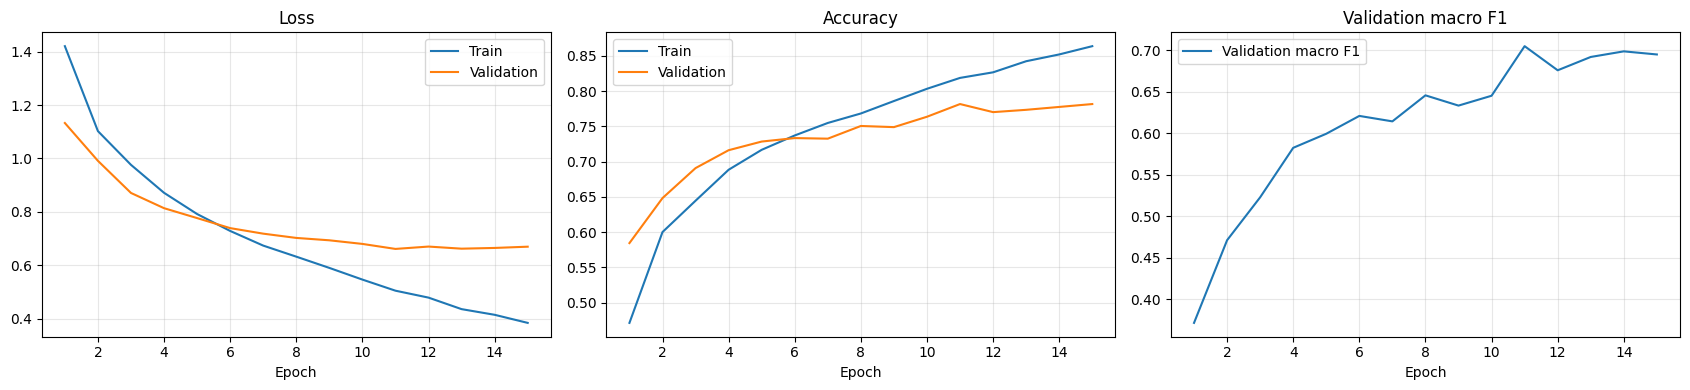

In [100]:
if RUN_EXPERIMENT_1:
    training_history = pd.DataFrame(stage_2_history)
    
    history_x = np.arange(1, len(training_history) + 1)
    fig, axes = plt.subplots(1, 3, figsize=(17, 4))
    
    axes[0].plot(history_x, training_history["train_loss"], label="Train")
    axes[0].plot(history_x, training_history["validation_loss"], label="Validation")
    axes[0].set_title("Loss")
    axes[0].legend()
    
    axes[1].plot(history_x, training_history["train_accuracy"], label="Train")
    axes[1].plot(history_x, training_history["validation_accuracy"], label="Validation")
    axes[1].set_title("Accuracy")
    axes[1].legend()
    
    axes[2].plot(history_x, training_history["validation_macro_f1"], label="Validation macro F1")
    axes[2].set_title("Validation macro F1")
    axes[2].legend()
    
    for axis in axes:
        axis.set_xlabel("Epoch")
        axis.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

### 5.2 Expt 1. Detailed Evaluation

In [101]:
if RUN_EXPERIMENT_1:
    test_targets, test_predictions, incorrect_test_examples = collect_test_predictions(
        baseline_model, test_loader
    )
    baseline_test_metrics = calculate_test_metrics(test_targets, test_predictions)

Baseline per-class classification report:
              precision    recall  f1-score   support

    Surprise     0.7290    0.7112    0.7200       329
        Fear     0.6400    0.4324    0.5161        74
     Disgust     0.3901    0.3438    0.3654       160
       Happy     0.8829    0.8970    0.8899      1185
         Sad     0.6964    0.7343    0.7149       478
       Angry     0.6768    0.6852    0.6810       162
     Neutral     0.6988    0.7029    0.7009       680

    accuracy                         0.7575      3068
   macro avg     0.6734    0.6438    0.6555      3068
weighted avg     0.7541    0.7575    0.7551      3068



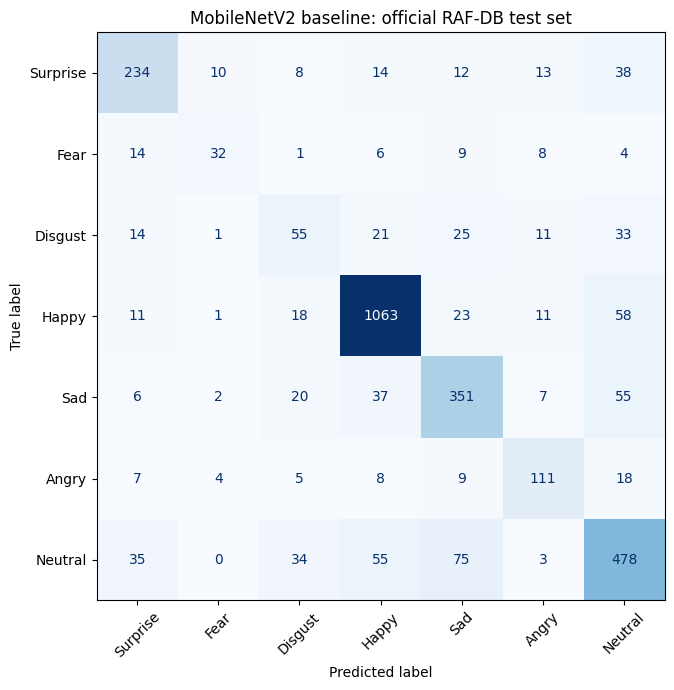

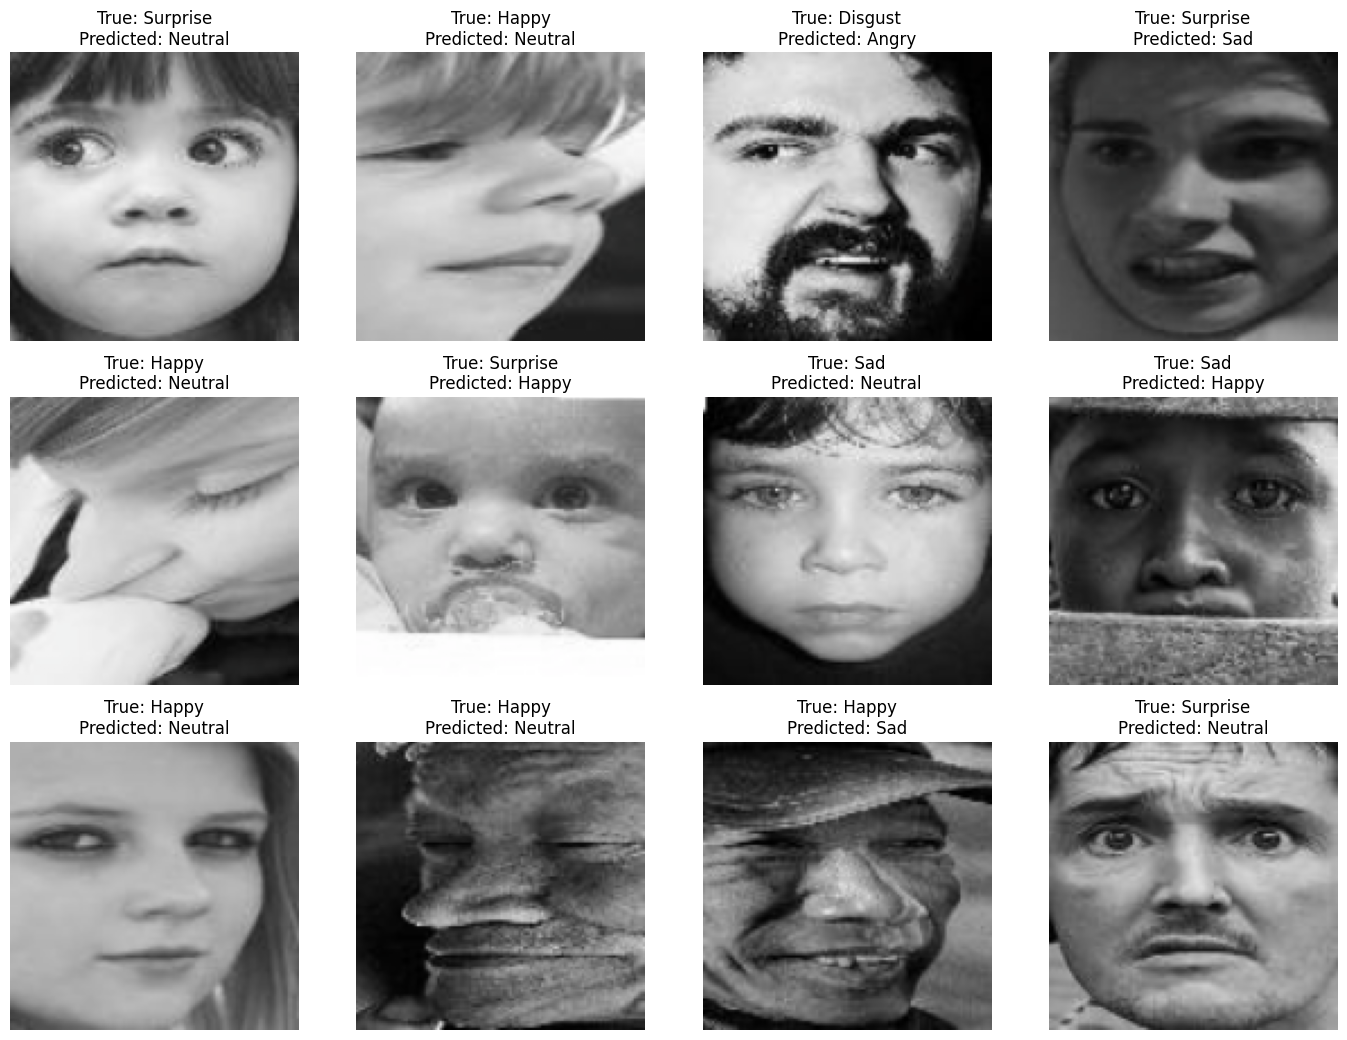

In [102]:
if RUN_EXPERIMENT_1:
    print("Baseline per-class classification report:")
    print(
        classification_report(
            test_targets,
            test_predictions,
            labels=list(range(len(CLASS_NAMES))),
            target_names=CLASS_NAMES,
            digits=4,
            zero_division=0,
        )
    )
    
    test_confusion_matrix = confusion_matrix(
        test_targets, test_predictions, labels=list(range(len(CLASS_NAMES)))
    )
    fig, axis = plt.subplots(figsize=(8, 7))
    ConfusionMatrixDisplay(test_confusion_matrix, display_labels=CLASS_NAMES).plot(
        ax=axis, cmap="Blues", xticks_rotation=45, colorbar=False
    )
    axis.set_title("MobileNetV2 baseline: official RAF-DB test set")
    plt.tight_layout()
    plt.show()
    
    if incorrect_test_examples:
        columns = 4
        rows = int(np.ceil(len(incorrect_test_examples) / columns))
        fig, axes = plt.subplots(rows, columns, figsize=(14, 3.5 * rows))
        axes = np.asarray(axes).reshape(-1)
    
        for axis, (image_tensor, true_index, predicted_index, path) in zip(
            axes, incorrect_test_examples
        ):
            axis.imshow(tensor_for_display(image_tensor))
            axis.set_title(
                f"True: {CLASS_NAMES[true_index]}\nPredicted: {CLASS_NAMES[predicted_index]}"
            )
            axis.axis("off")
    
        for axis in axes[len(incorrect_test_examples):]:
            axis.axis("off")
        plt.tight_layout()
        plt.show()
    else:
        print("No incorrectly classified test images were found.")

## 6. Expt 2 - MobileNetV2 - No augmentation, unweighted

In [103]:
if RUN_EXPERIMENT_2:
    reset_experiment_seed()
    no_augmentation_train_loader = DataLoader(
        RAFDBDataset(train_dataframe, evaluation_transform),
        shuffle=True, **loader_options,
    )
    no_augmentation_model = create_model()
    no_augmentation_model, no_augmentation_test_metrics, _ = run_backbone_experiment(
        no_augmentation_model, no_augmentation_model.classifier,
        "MobileNetV2 No Augmentation",
        NO_AUGMENTATION_STAGE_1_CHECKPOINT, NO_AUGMENTATION_CHECKPOINT,
        no_augmentation_train_loader, validation_loader, test_loader,
    )
else:
    print("Experiment 2 skipped.")

MobileNetV2 No Augmentation Stage 1 | Epoch 01/4 | train loss 1.5133, acc 0.4329 | val loss 1.3540, acc 0.5041, macro F1 0.2676 | time 9.6s
  Saved improved checkpoint to best_mobilenetv2_no_augmentation_stage1.pt
MobileNetV2 No Augmentation Stage 1 | Epoch 02/4 | train loss 1.3308, acc 0.5079 | val loss 1.2668, acc 0.5278, macro F1 0.3131 | time 9.4s
  Saved improved checkpoint to best_mobilenetv2_no_augmentation_stage1.pt
MobileNetV2 No Augmentation Stage 1 | Epoch 03/4 | train loss 1.2645, acc 0.5346 | val loss 1.2207, acc 0.5565, macro F1 0.3613 | time 9.6s
  Saved improved checkpoint to best_mobilenetv2_no_augmentation_stage1.pt
MobileNetV2 No Augmentation Stage 1 | Epoch 04/4 | train loss 1.2293, acc 0.5438 | val loss 1.1927, acc 0.5638, macro F1 0.3766 | time 9.5s
  Saved improved checkpoint to best_mobilenetv2_no_augmentation_stage1.pt
MobileNetV2 No Augmentation Stage 1 completed in 0.64 minutes.
MobileNetV2 No Augmentation Stage 2 | Epoch 01/15 | train loss 1.4089, acc 0.4759

## 7. Expt 3 - MobileNetV2 - Augmented, class-weighted

In [104]:
if RUN_EXPERIMENT_3:
    class_counts = train_dataframe["label_index"].value_counts().sort_index()
    class_weights = len(train_dataframe) / (len(CLASS_NAMES) * class_counts.to_numpy())
    class_weights = torch.tensor(class_weights, dtype=torch.float32, device=device)
    print("Class weights:", dict(zip(CLASS_NAMES, class_weights.cpu().tolist())))

    reset_experiment_seed()
    weighted_model = create_model()
    weighted_model, weighted_test_metrics, _ = run_backbone_experiment(
        weighted_model, weighted_model.classifier, "Weighted MobileNetV2",
        WEIGHTED_STAGE_1_CHECKPOINT, WEIGHTED_CHECKPOINT,
        train_loader, validation_loader, test_loader,
        criterion=nn.CrossEntropyLoss(weight=class_weights),
    )
else:
    print("Experiment 3 skipped.")

Class weights: {'Surprise': 1.357945442199707, 'Fear': 6.210050582885742, 'Disgust': 2.4396629333496094, 'Happy': 0.3676047921180725, 'Sad': 0.8811793923377991, 'Angry': 2.4899253845214844, 'Neutral': 0.6964285969734192}
Weighted MobileNetV2 Stage 1 | Epoch 01/4 | train loss 1.7783, acc 0.3003 | val loss 1.6330, acc 0.4321, macro F1 0.3679 | time 13.5s
  Saved improved checkpoint to best_mobilenetv2_weighted_stage1.pt
Weighted MobileNetV2 Stage 1 | Epoch 02/4 | train loss 1.6245, acc 0.4143 | val loss 1.5737, acc 0.3715, macro F1 0.3134 | time 13.5s
Weighted MobileNetV2 Stage 1 | Epoch 03/4 | train loss 1.5593, acc 0.4232 | val loss 1.5217, acc 0.4918, macro F1 0.3968 | time 13.5s
  Saved improved checkpoint to best_mobilenetv2_weighted_stage1.pt
Weighted MobileNetV2 Stage 1 | Epoch 04/4 | train loss 1.5307, acc 0.4333 | val loss 1.4853, acc 0.4763, macro F1 0.3903 | time 13.5s
Weighted MobileNetV2 Stage 1 completed in 0.90 minutes.
Weighted MobileNetV2 Stage 2 | Epoch 01/15 | train lo

## 8. Expt 4 - MobileNetV2 - Augmented, random oversampling

In [105]:
if RUN_EXPERIMENT_4:
    reset_experiment_seed()
    oversampled_loaders = create_oversampled_loaders(
        train_transform, evaluation_transform
    )
    oversampled_model = create_model()
    oversampled_model, oversampled_test_metrics, _ = run_backbone_experiment(
        oversampled_model, oversampled_model.classifier, "Oversampled MobileNetV2",
        OVERSAMPLED_STAGE_1_CHECKPOINT, OVERSAMPLED_CHECKPOINT,
        *oversampled_loaders,
    )
else:
    print("Experiment 4 skipped.")

Oversampled MobileNetV2 Stage 1 | Epoch 01/4 | train loss 1.7437, acc 0.3247 | val loss 1.6021, acc 0.4542, macro F1 0.3799 | time 13.5s
  Saved improved checkpoint to best_mobilenetv2_oversampled_stage1.pt
Oversampled MobileNetV2 Stage 1 | Epoch 02/4 | train loss 1.5793, acc 0.4083 | val loss 1.5721, acc 0.4354, macro F1 0.3731 | time 13.3s
Oversampled MobileNetV2 Stage 1 | Epoch 03/4 | train loss 1.5166, acc 0.4363 | val loss 1.4825, acc 0.4820, macro F1 0.4188 | time 13.4s
  Saved improved checkpoint to best_mobilenetv2_oversampled_stage1.pt
Oversampled MobileNetV2 Stage 1 | Epoch 04/4 | train loss 1.4934, acc 0.4497 | val loss 1.4971, acc 0.4476, macro F1 0.3861 | time 13.4s
Oversampled MobileNetV2 Stage 1 completed in 0.89 minutes.
Oversampled MobileNetV2 Stage 2 | Epoch 01/15 | train loss 1.6195, acc 0.3745 | val loss 1.4465, acc 0.4525, macro F1 0.3823 | time 15.5s
  Saved improved checkpoint to best_mobilenetv2_oversampled.pt
Oversampled MobileNetV2 Stage 2 | Epoch 02/15 | trai

## 9. Expt 5 - MobileNetV2 - RGB, augmented, random oversampling

This experiment keeps the original RGB channels while using the same augmentation and oversampling strategy as Experiment 4.

In [106]:
if RUN_EXPERIMENT_5:
    reset_experiment_seed()
    rgb_loaders = create_oversampled_loaders(
        rgb_train_transform, rgb_evaluation_transform
    )
    rgb_oversampled_model = create_model()
    rgb_oversampled_model, rgb_oversampled_test_metrics, _ = run_backbone_experiment(
        rgb_oversampled_model, rgb_oversampled_model.classifier,
        "RGB Oversampled MobileNetV2",
        RGB_OVERSAMPLED_STAGE_1_CHECKPOINT, RGB_OVERSAMPLED_CHECKPOINT,
        *rgb_loaders,
    )
else:
    print("Experiment 5 skipped.")

RGB Oversampled MobileNetV2 Stage 1 | Epoch 01/4 | train loss 1.7304, acc 0.3382 | val loss 1.5607, acc 0.4624, macro F1 0.3790 | time 12.6s
  Saved improved checkpoint to best_mobilenetv2_rgb_oversampled_stage1.pt
RGB Oversampled MobileNetV2 Stage 1 | Epoch 02/4 | train loss 1.5704, acc 0.4189 | val loss 1.5502, acc 0.4607, macro F1 0.3900 | time 12.6s
  Saved improved checkpoint to best_mobilenetv2_rgb_oversampled_stage1.pt
RGB Oversampled MobileNetV2 Stage 1 | Epoch 03/4 | train loss 1.5118, acc 0.4373 | val loss 1.4696, acc 0.4926, macro F1 0.4217 | time 12.6s
  Saved improved checkpoint to best_mobilenetv2_rgb_oversampled_stage1.pt
RGB Oversampled MobileNetV2 Stage 1 | Epoch 04/4 | train loss 1.4879, acc 0.4494 | val loss 1.4729, acc 0.4935, macro F1 0.4084 | time 12.6s
RGB Oversampled MobileNetV2 Stage 1 completed in 0.84 minutes.
RGB Oversampled MobileNetV2 Stage 2 | Epoch 01/15 | train loss 1.6077, acc 0.3834 | val loss 1.4324, acc 0.4763, macro F1 0.4130 | time 14.7s
  Saved i

## 10. Expt 6 - MobileNetV3-Large Baseline - Augmented, unweighted

This experiment changes only the model.  This model has 5.48M parameters and 0.22 GFLOPs compared to MobileNetV2's 3.50M parameters and 0.30 GFLOPs

In [107]:
if RUN_EXPERIMENT_6:
    reset_experiment_seed()
    mobilenetv3_model = mobilenet_v3_large(weights=MobileNet_V3_Large_Weights.DEFAULT)
    mobilenetv3_model.classifier[-1] = nn.Linear(
        mobilenetv3_model.classifier[-1].in_features, len(CLASS_NAMES)
    )
    mobilenetv3_model = mobilenetv3_model.to(device)
    mobilenetv3_model, mobilenetv3_test_metrics, _ = run_backbone_experiment(
        mobilenetv3_model, mobilenetv3_model.classifier, "MobileNetV3-Large",
        MOBILENETV3_STAGE_1_CHECKPOINT, MOBILENETV3_CHECKPOINT,
        train_loader, validation_loader, test_loader,
    )
else:
    print("Experiment 6 skipped.")

MobileNetV3-Large Stage 1 | Epoch 01/4 | train loss 1.3900, acc 0.4836 | val loss 1.2043, acc 0.5728, macro F1 0.3859 | time 13.0s
  Saved improved checkpoint to best_mobilenetv3_large_stage1.pt
MobileNetV3-Large Stage 1 | Epoch 02/4 | train loss 1.2017, acc 0.5648 | val loss 1.1662, acc 0.5687, macro F1 0.4041 | time 13.0s
  Saved improved checkpoint to best_mobilenetv3_large_stage1.pt
MobileNetV3-Large Stage 1 | Epoch 03/4 | train loss 1.1367, acc 0.5838 | val loss 1.1602, acc 0.5769, macro F1 0.4496 | time 13.0s
  Saved improved checkpoint to best_mobilenetv3_large_stage1.pt
MobileNetV3-Large Stage 1 | Epoch 04/4 | train loss 1.0980, acc 0.5940 | val loss 1.1448, acc 0.5867, macro F1 0.4315 | time 12.9s
MobileNetV3-Large Stage 1 completed in 0.87 minutes.
MobileNetV3-Large Stage 2 | Epoch 01/15 | train loss 1.4266, acc 0.4895 | val loss 1.1346, acc 0.5982, macro F1 0.4113 | time 15.2s
  Saved improved checkpoint to best_mobilenetv3_large.pt
MobileNetV3-Large Stage 2 | Epoch 02/15 | 

## 11. Expt 7 - EfficientNet-B0 - RGB, augmented, random oversampling

EfficientNet-B0 is evaluated with the same RGB preprocessing, augmentation, oversampling, and training schedule as Experiment 5.

In [108]:
if RUN_EXPERIMENT_7:
    reset_experiment_seed()
    efficientnet_loaders = create_oversampled_loaders(
        rgb_train_transform, rgb_evaluation_transform
    )
    efficientnet_model = efficientnet_b0(weights=EfficientNet_B0_Weights.DEFAULT)
    efficientnet_model.classifier[-1] = nn.Linear(
        efficientnet_model.classifier[-1].in_features, len(CLASS_NAMES)
    )
    efficientnet_model = efficientnet_model.to(device)
    efficientnet_model, efficientnet_test_metrics, _ = run_backbone_experiment(
        efficientnet_model, efficientnet_model.classifier, "EfficientNet-B0",
        EFFICIENTNET_STAGE_1_CHECKPOINT, EFFICIENTNET_CHECKPOINT,
        *efficientnet_loaders,
    )
else:
    print("Experiment 7 skipped.")

Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to C:\Users\ADAM-/.cache\torch\hub\checkpoints\efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 48.5MB/s]


EfficientNet-B0 Stage 1 | Epoch 01/4 | train loss 1.6599, acc 0.3739 | val loss 1.5605, acc 0.4116, macro F1 0.3398 | time 13.4s
  Saved improved checkpoint to best_efficientnet_b0_stage1.pt
EfficientNet-B0 Stage 1 | Epoch 02/4 | train loss 1.4711, acc 0.4594 | val loss 1.4979, acc 0.4493, macro F1 0.3749 | time 12.9s
  Saved improved checkpoint to best_efficientnet_b0_stage1.pt
EfficientNet-B0 Stage 1 | Epoch 03/4 | train loss 1.3979, acc 0.4901 | val loss 1.4128, acc 0.5008, macro F1 0.4155 | time 13.0s
  Saved improved checkpoint to best_efficientnet_b0_stage1.pt
EfficientNet-B0 Stage 1 | Epoch 04/4 | train loss 1.3604, acc 0.4990 | val loss 1.4209, acc 0.5025, macro F1 0.4151 | time 12.7s
EfficientNet-B0 Stage 1 completed in 0.87 minutes.
EfficientNet-B0 Stage 2 | Epoch 01/15 | train loss 1.5770, acc 0.3993 | val loss 1.3747, acc 0.4722, macro F1 0.4004 | time 15.5s
  Saved improved checkpoint to best_efficientnet_b0.pt
EfficientNet-B0 Stage 2 | Epoch 02/15 | train loss 1.2013, acc

## 12. Expt 8 - ResNet-18 - RGB, augmented, random oversampling

ResNet-18 provides a higher-capacity reference using the same RGB oversampling protocol.

In [109]:
if RUN_EXPERIMENT_8:
    reset_experiment_seed()
    resnet18_loaders = create_oversampled_loaders(
        rgb_train_transform, rgb_evaluation_transform
    )
    resnet18_model = resnet18(weights=ResNet18_Weights.DEFAULT)
    resnet18_model.fc = nn.Linear(resnet18_model.fc.in_features, len(CLASS_NAMES))
    resnet18_model = resnet18_model.to(device)
    resnet18_model, resnet18_test_metrics, _ = run_backbone_experiment(
        resnet18_model, resnet18_model.fc, "ResNet-18",
        RESNET18_STAGE_1_CHECKPOINT, RESNET18_CHECKPOINT,
        *resnet18_loaders,
    )
else:
    print("Experiment 8 skipped.")

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to C:\Users\ADAM-/.cache\torch\hub\checkpoints\resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 50.1MB/s]


ResNet-18 Stage 1 | Epoch 01/4 | train loss 1.7493, acc 0.3167 | val loss 1.7206, acc 0.3535, macro F1 0.3080 | time 12.1s
  Saved improved checkpoint to best_resnet18_stage1.pt
ResNet-18 Stage 1 | Epoch 02/4 | train loss 1.5724, acc 0.4091 | val loss 1.6130, acc 0.3936, macro F1 0.3361 | time 12.2s
  Saved improved checkpoint to best_resnet18_stage1.pt
ResNet-18 Stage 1 | Epoch 03/4 | train loss 1.5205, acc 0.4364 | val loss 1.5829, acc 0.4280, macro F1 0.3674 | time 12.2s
  Saved improved checkpoint to best_resnet18_stage1.pt
ResNet-18 Stage 1 | Epoch 04/4 | train loss 1.5039, acc 0.4376 | val loss 1.5059, acc 0.4566, macro F1 0.3834 | time 12.3s
  Saved improved checkpoint to best_resnet18_stage1.pt
ResNet-18 Stage 1 completed in 0.81 minutes.
ResNet-18 Stage 2 | Epoch 01/15 | train loss 1.2101, acc 0.5563 | val loss 1.0054, acc 0.6334, macro F1 0.5549 | time 14.2s
  Saved improved checkpoint to best_resnet18.pt
ResNet-18 Stage 2 | Epoch 02/15 | train loss 0.7022, acc 0.7516 | val l

## 13. BTFER external cross-dataset evaluation

BTFER is used only for external evaluation

In [110]:
BTFER_DIR = Path("BTFER")
SUPPORTED_IMAGE_SUFFIXES = {".jpg", ".jpeg", ".png"}

btfer_rows = []
for class_folder in sorted(BTFER_DIR.iterdir()):
    if not class_folder.is_dir():
        continue
    label_name = class_folder.name
    label_index = CLASS_NAMES.index(label_name)
    for image_path in sorted(class_folder.iterdir()):
        if image_path.is_file() and image_path.suffix.lower() in SUPPORTED_IMAGE_SUFFIXES:
            btfer_rows.append({
                "image_path": image_path,
                "label_name": label_name,
                "label_index": label_index,
                "source_folder": class_folder.name,
            })

btfer_dataframe = pd.DataFrame(btfer_rows)
original_class_counts = (
    btfer_dataframe["label_name"].value_counts().reindex(CLASS_NAMES, fill_value=0)
)
if len(btfer_dataframe) != 2100 or not (original_class_counts == 300).all():
    raise ValueError(
        "Expected BTFER to contain exactly 300 images for each of the seven classes."
    )

def calculate_sha256(image_path):
    with open(image_path, "rb") as image_file:
        return hashlib.sha256(image_file.read()).hexdigest()

# Check exact duplicates by comparing file-content hashes.
btfer_dataframe["content_hash"] = btfer_dataframe["image_path"].apply(calculate_sha256)
hash_stats = btfer_dataframe.groupby("content_hash").agg(
    copies=("image_path", "size"),
    labels=("label_name", "nunique"),
)
duplicate_groups = hash_stats[hash_stats["copies"] > 1]
conflicting_hashes = set(duplicate_groups.index[duplicate_groups["labels"] > 1])

print(f"Original images: {len(btfer_dataframe):,}")
print(f"Unique images: {btfer_dataframe['content_hash'].nunique():,}")
print(f"Duplicate groups: {len(duplicate_groups):,}")
print(f"Extra duplicate files: {(duplicate_groups['copies'] - 1).sum():,}")
print(f"Cross-class conflict groups: {len(conflicting_hashes):,}")

# Remove every cross-class conflict, then keep one copy of same-class duplicates.
original_image_count = len(btfer_dataframe)
btfer_dataframe = (
    btfer_dataframe[~btfer_dataframe["content_hash"].isin(conflicting_hashes)]
    .drop_duplicates(subset="content_hash", keep="first")
    .reset_index(drop=True)
)

if btfer_dataframe["content_hash"].duplicated().any():
    raise AssertionError("Duplicate hashes remain after cleaning.")

btfer_class_counts = (
    btfer_dataframe["label_name"].value_counts().reindex(CLASS_NAMES, fill_value=0)
)
print(f"Removed images: {original_image_count - len(btfer_dataframe):,}")
print(f"Cleaned images: {len(btfer_dataframe):,}")
print("Cleaned class counts:")
for class_name, count in btfer_class_counts.items():
    print(f"  {class_name}: {count}")
print("Original files were not deleted; only btfer_dataframe was cleaned.")

btfer_dataset = RAFDBDataset(btfer_dataframe, evaluation_transform)
btfer_loader = DataLoader(btfer_dataset, shuffle=False, **loader_options)
btfer_images, btfer_labels, _ = next(iter(btfer_loader))
print(f"BTFER batch shape after preprocessing: {tuple(btfer_images.shape)}")

btfer_models = {}
if RUN_EXPERIMENT_1:
    btfer_models["MobileNetV2 - Baseline"] = (baseline_model, btfer_loader)
if RUN_EXPERIMENT_2:
    btfer_models["MobileNetV2 - No augmentation"] = (no_augmentation_model, btfer_loader)
if RUN_EXPERIMENT_3:
    btfer_models["MobileNetV2 - Class-weighted"] = (weighted_model, btfer_loader)
if RUN_EXPERIMENT_4:
    btfer_models["MobileNetV2 - Oversampled"] = (oversampled_model, btfer_loader)
if any([RUN_EXPERIMENT_5, RUN_EXPERIMENT_7, RUN_EXPERIMENT_8]):
    rgb_btfer_dataset = RAFDBDataset(btfer_dataframe, rgb_evaluation_transform)
    rgb_btfer_loader = DataLoader(rgb_btfer_dataset, shuffle=False, **loader_options)
if RUN_EXPERIMENT_5:
    btfer_models["MobileNetV2 - RGB oversampled"] = (
        rgb_oversampled_model, rgb_btfer_loader
    )
if RUN_EXPERIMENT_6:
    btfer_models["MobileNetV3-Large - Baseline"] = (mobilenetv3_model, btfer_loader)
if RUN_EXPERIMENT_7:
    btfer_models["EfficientNet-B0 - RGB oversampled"] = (
        efficientnet_model, rgb_btfer_loader
    )
if RUN_EXPERIMENT_8:
    btfer_models["ResNet-18 - RGB oversampled"] = (
        resnet18_model, rgb_btfer_loader
    )

btfer_results = {}
for experiment_name, (model, evaluation_loader) in btfer_models.items():
    targets, predictions, _ = collect_test_predictions(
        model, evaluation_loader, maximum_errors=0
    )
    btfer_results[experiment_name] = calculate_test_metrics(targets, predictions)

if not btfer_results:
    print("BTFER model evaluation skipped because no experiments were enabled.")

Original images: 2,100
Unique images: 1,921
Duplicate groups: 162
Extra duplicate files: 179
Cross-class conflict groups: 5
Removed images: 184
Cleaned images: 1,916
Cleaned class counts:
  Surprise: 291
  Fear: 255
  Disgust: 267
  Happy: 296
  Sad: 273
  Angry: 271
  Neutral: 263
Original files were not deleted; only btfer_dataframe was cleaned.
BTFER batch shape after preprocessing: (128, 3, 128, 128)


## 14. Comprehensive experiments comparison

The table compares predictive performance with three edge-deployment indicators. Latency is model-only, batch-size-one FP32 inference; p95 at or below 33.3 ms meets a 30 FPS model budget. Peak memory combines model state and peak inference activations.

In [113]:
rafdb_results = {}
if RUN_EXPERIMENT_1:
    rafdb_results["MobileNetV2 - Baseline"] = baseline_test_metrics
if RUN_EXPERIMENT_2:
    rafdb_results["MobileNetV2 - No augmentation"] = no_augmentation_test_metrics
if RUN_EXPERIMENT_3:
    rafdb_results["MobileNetV2 - Class-weighted"] = weighted_test_metrics
if RUN_EXPERIMENT_4:
    rafdb_results["MobileNetV2 - Oversampled"] = oversampled_test_metrics
if RUN_EXPERIMENT_5:
    rafdb_results["MobileNetV2 - RGB oversampled"] = rgb_oversampled_test_metrics
if RUN_EXPERIMENT_6:
    rafdb_results["MobileNetV3-Large - Baseline"] = mobilenetv3_test_metrics
if RUN_EXPERIMENT_7:
    rafdb_results["EfficientNet-B0 - RGB oversampled"] = efficientnet_test_metrics
if RUN_EXPERIMENT_8:
    rafdb_results["ResNet-18 - RGB oversampled"] = resnet18_test_metrics

deployment_results = {
    experiment_name: measure_deployment_metrics(model)
    for experiment_name, (model, _) in btfer_models.items()
}

comparison_rows = {}
for experiment_name, rafdb_metrics in rafdb_results.items():
    if experiment_name not in btfer_results:
        raise KeyError(f"Missing BTFER metrics for {experiment_name}")
    btfer_metrics = btfer_results[experiment_name]
    comparison_rows[experiment_name] = {
        "RAF-DB accuracy": rafdb_metrics["accuracy"],
        "RAF-DB macro F1": rafdb_metrics["macro_f1"],
        "BTFER accuracy": btfer_metrics["accuracy"],
        "BTFER macro F1": btfer_metrics["macro_f1"],
        **deployment_results[experiment_name],
    }

final_results_table = pd.DataFrame.from_dict(comparison_rows, orient="index")
final_results_table.index.name = "Training experiment"

performance_columns = [
    "RAF-DB accuracy",
    "RAF-DB macro F1",
    "BTFER accuracy",
    "BTFER macro F1",
]
resource_columns = [
    "Parameters (M)", "p95 latency (ms)", "Peak inference memory (MB)"
]

if final_results_table.empty:
    results_style = None
    print("No experiment results to compare.")
else:
    results_style = (
        final_results_table.style
        .format({
            **{column: "{:.1%}" for column in performance_columns},
            "Parameters (M)": "{:.2f}",
            "p95 latency (ms)": "{:.2f}",
            "Peak inference memory (MB)": "{:.1f}",
        }, na_rep="N/A")
        .highlight_max(
            subset=performance_columns, axis=0,
            props="background-color: #c6efce !important; color: #006100 !important; font-weight: 700;",
        )
        .highlight_min(
            subset=resource_columns, axis=0,
            props="background-color: #c6efce !important; color: #006100 !important; font-weight: 700;",
        )
        .set_caption("FER accuracy and edge-deployment comparison")
        .set_properties(**{"text-align": "center", "color": "#111111"})
        .set_table_styles([
            {"selector": "table", "props": [
                ("background-color", "grey"), ("color", "#111111"),
                ("border-collapse", "collapse"),
            ]},
            {"selector": "caption", "props": [
                ("caption-side", "top"), ("font-size", "15px"),
                ("font-weight", "700"), ("color", "#111111"),
                ("background-color", "grey"), ("padding", "8px"),
            ]},
            {"selector": "th.col_heading", "props": [
                ("background-color", "grey"), ("color", "#111111"),
                ("font-weight", "700"), ("text-align", "center"),
                ("padding", "7px 10px"),
            ]},
            {"selector": "th.blank", "props": [
                ("background-color", "grey"), ("color", "#111111"),
            ]},
            {"selector": "th.row_heading", "props": [
                ("background-color", "grey"), ("color", "#111111"),
                ("text-align", "left"), ("font-weight", "700"),
                ("white-space", "nowrap"), ("padding", "7px 10px"),
            ]},
            {"selector": "td", "props": [
                ("background-color", "white"), ("color", "#111111"),
                ("border", "1px solid #dddddd"), ("padding", "7px 10px"),
            ]},
        ])
    )
    
    print(f"Latency benchmark: batch size 1, FP32, {device}, {IMAGE_SIZE}x{IMAGE_SIZE}")
    print("p95 latency <= 33.3 ms indicates model-only 30 FPS capability.")
    display(results_style)

Latency benchmark: batch size 1, FP32, cuda, 128x128
p95 latency <= 33.3 ms indicates model-only 30 FPS capability.


,RAF-DB accuracy,RAF-DB macro F1,BTFER accuracy,BTFER macro F1,Parameters (M),p95 latency (ms),Peak inference memory (MB)
Training experiment,,,,,,,
MobileNetV2 - Baseline,75.7%,65.5%,54.7%,51.6%,2.23,3.28,12.4
MobileNetV2 - No augmentation,67.2%,55.7%,45.0%,42.1%,2.23,2.97,12.4
MobileNetV2 - Class-weighted,72.6%,63.8%,52.7%,51.3%,2.23,2.95,12.4
MobileNetV2 - Oversampled,74.9%,66.2%,55.1%,54.1%,2.23,2.76,12.4
MobileNetV2 - RGB oversampled,75.9%,67.6%,52.8%,50.3%,2.23,2.66,12.4
MobileNetV3-Large - Baseline,75.7%,66.2%,50.3%,47.7%,4.21,3.42,19.4
EfficientNet-B0 - RGB oversampled,77.5%,69.5%,54.9%,52.3%,4.02,4.76,19.3
ResNet-18 - RGB oversampled,79.2%,70.0%,52.8%,51.1%,11.18,1.58,57.7
